In [ ]:
import pandas as pd
import numpy as np

file_path = "/content/weather.csv"

df = pd.read_csv(file_path)


/tmp/ipykernel_581/3480644026.py:6: DtypeWarning: Columns (19,20,28) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


In [ ]:

# Clean column names
df.columns = df.columns.str.strip()

print("Original Shape:", df.shape)
print("\nOriginal Columns:")
print(df.columns.tolist())

Original Shape: (84055, 29)

Original Columns:
['city', 'state', 'latitude', 'longitude', 'date', 'year', 'month', 'day_of_year', 'decade', 'weather_code', 'temp_max_c', 'temp_min_c', 'temp_range_c', 'apparent_temp_max_c', 'apparent_temp_min_c', 'precipitation_mm', 'rain_mm', 'snowfall_cm', 'precipitation_hours', 'is_monsoon_season', 'heatwave_day_simple_flag', 'sunshine_duration_sec', 'daylight_duration_sec', 'wind_speed_max_kmh', 'wind_gusts_max_kmh', 'wind_direction_dominant_deg', 'solar_radiation_mj_m2', 'reference_evapotranspiration_mm', 'has_missing_values']


In [ ]:

columns_to_remove = [
    "latitude",
    "longitude",
    "date",
    "month",
    "date_of_year",
    "day_of_year",
    "decade",
    "city"
]

# Remove only columns that actually exist
existing_columns = [
    col for col in columns_to_remove
    if col in df.columns
]

df = df.drop(columns=existing_columns)

print("\nRemoved Columns:")
print(existing_columns)


Removed Columns:
['latitude', 'longitude', 'date', 'month', 'day_of_year', 'decade', 'city']


In [ ]:

if "state" not in df.columns:
    raise ValueError("State column not found!")

print("\nNumber of States:",
      df["state"].nunique())

print("\nStates:")
print(df["state"].unique())

# All columns except state
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("\nNumeric Columns:")
print(numeric_columns)

state_wise_df = df.groupby(
    "state",
    as_index=False
)[numeric_columns].mean()


state_wise_df[numeric_columns] = (
    state_wise_df[numeric_columns].round(2)
)



Number of States: 3

States:
['Tripura' 'Uttar Pradesh' 'Gujarat']

Numeric Columns:
['year', 'weather_code', 'temp_max_c', 'temp_min_c', 'temp_range_c', 'apparent_temp_max_c', 'apparent_temp_min_c', 'precipitation_mm', 'rain_mm', 'snowfall_cm', 'precipitation_hours', 'sunshine_duration_sec', 'daylight_duration_sec', 'wind_speed_max_kmh', 'wind_gusts_max_kmh', 'wind_direction_dominant_deg', 'solar_radiation_mj_m2', 'reference_evapotranspiration_mm']


In [ ]:


print("\nFinal State-Wise Dataset:")
display(state_wise_df)

print("\nFinal Shape:",
      state_wise_df.shape)

print("\nMissing Values:")
print(state_wise_df.isnull().sum())

output_file = "/content/india_statewise_climate.csv"

state_wise_df.to_csv(
    output_file,
    index=False
)

print("\nSaved successfully!")
print(output_file)


Final State-Wise Dataset:


,state,year,weather_code,temp_max_c,temp_min_c,temp_range_c,apparent_temp_max_c,apparent_temp_min_c,precipitation_mm,rain_mm,snowfall_cm,precipitation_hours,sunshine_duration_sec,daylight_duration_sec,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,solar_radiation_mj_m2,reference_evapotranspiration_mm
0,Gujarat,1967.99,16.88,33.18,21.61,11.57,34.63,22.42,1.71,1.71,0.0,2.54,37115.23,43737.29,14.72,30.67,195.68,19.66,5.27
1,Tripura,1982.79,35.55,29.96,21.10,8.86,33.89,23.90,5.48,5.48,0.0,6.08,32558.59,43751.41,12.58,28.05,175.11,16.13,3.48
2,Uttar Pradesh,1982.79,19.54,31.44,19.89,11.54,33.03,20.67,2.07,2.07,0.0,2.71,37343.56,43782.38,13.73,28.13,215.04,19.10,4.80



Final Shape: (3, 19)

Missing Values:
state                              0
year                               0
weather_code                       0
temp_max_c                         0
temp_min_c                         0
temp_range_c                       0
apparent_temp_max_c                0
apparent_temp_min_c                0
precipitation_mm                   0
rain_mm                            0
snowfall_cm                        0
precipitation_hours                0
sunshine_duration_sec              0
daylight_duration_sec              0
wind_speed_max_kmh                 0
wind_gusts_max_kmh                 0
wind_direction_dominant_deg        0
solar_radiation_mj_m2              0
reference_evapotranspiration_mm    0
dtype: int64

Saved successfully!
/content/india_statewise_climate.csv


In [ ]:
# ============================================================
# EDA - EXPLORATORY DATA ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ------------------------------------------------------------
# 1. BASIC INFORMATION
# ------------------------------------------------------------

print("========== DATASET SHAPE ==========")
print(state_wise_df.shape)

print("\n========== DATASET INFO ==========")
state_wise_df.info()


# ------------------------------------------------------------
# 2. FIRST 5 ROWS
# ------------------------------------------------------------

print("\n========== FIRST 5 ROWS ==========")
display(state_wise_df.head())



========== DATASET SHAPE ==========
(3, 19)

========== DATASET INFO ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   state                            3 non-null      object 
 1   year                             3 non-null      float64
 2   weather_code                     3 non-null      float64
 3   temp_max_c                       3 non-null      float64
 4   temp_min_c                       3 non-null      float64
 5   temp_range_c                     3 non-null      float64
 6   apparent_temp_max_c              3 non-null      float64
 7   apparent_temp_min_c              3 non-null      float64
 8   precipitation_mm                 3 non-null      float64
 9   rain_mm                          3 non-null      float64
 10  snowfall_cm                      3 non-null      float64
 11  precipit

,state,year,weather_code,temp_max_c,temp_min_c,temp_range_c,apparent_temp_max_c,apparent_temp_min_c,precipitation_mm,rain_mm,snowfall_cm,precipitation_hours,sunshine_duration_sec,daylight_duration_sec,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,solar_radiation_mj_m2,reference_evapotranspiration_mm
0,Gujarat,1967.99,16.88,33.18,21.61,11.57,34.63,22.42,1.71,1.71,0.0,2.54,37115.23,43737.29,14.72,30.67,195.68,19.66,5.27
1,Tripura,1982.79,35.55,29.96,21.10,8.86,33.89,23.90,5.48,5.48,0.0,6.08,32558.59,43751.41,12.58,28.05,175.11,16.13,3.48
2,Uttar Pradesh,1982.79,19.54,31.44,19.89,11.54,33.03,20.67,2.07,2.07,0.0,2.71,37343.56,43782.38,13.73,28.13,215.04,19.10,4.80



========== LAST 5 ROWS ==========


,state,year,weather_code,temp_max_c,temp_min_c,temp_range_c,apparent_temp_max_c,apparent_temp_min_c,precipitation_mm,rain_mm,snowfall_cm,precipitation_hours,sunshine_duration_sec,daylight_duration_sec,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,solar_radiation_mj_m2,reference_evapotranspiration_mm
0,Gujarat,1967.99,16.88,33.18,21.61,11.57,34.63,22.42,1.71,1.71,0.0,2.54,37115.23,43737.29,14.72,30.67,195.68,19.66,5.27
1,Tripura,1982.79,35.55,29.96,21.10,8.86,33.89,23.90,5.48,5.48,0.0,6.08,32558.59,43751.41,12.58,28.05,175.11,16.13,3.48
2,Uttar Pradesh,1982.79,19.54,31.44,19.89,11.54,33.03,20.67,2.07,2.07,0.0,2.71,37343.56,43782.38,13.73,28.13,215.04,19.10,4.80



========== STATISTICAL SUMMARY ==========


,year,weather_code,temp_max_c,temp_min_c,temp_range_c,apparent_temp_max_c,apparent_temp_min_c,precipitation_mm,rain_mm,snowfall_cm,precipitation_hours,sunshine_duration_sec,daylight_duration_sec,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,solar_radiation_mj_m2,reference_evapotranspiration_mm
count,3.000000,3.000000,3.000000,3.000000,3.000000,3.00000,3.00000,3.000000,3.000000,3.0,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
mean,1977.856667,23.990000,31.526667,20.866667,10.656667,33.85000,22.33000,3.086667,3.086667,0.0,3.776667,35672.460000,43757.026667,13.676667,28.950000,195.276667,18.296667,4.516667
std,8.544784,10.099213,1.611749,0.883421,1.556031,0.80075,1.61688,2.080489,2.080489,0.0,1.996555,2699.106043,23.063765,1.070996,1.490101,19.968055,1.897165,0.928027
min,1967.990000,16.880000,29.960000,19.890000,8.860000,33.03000,20.67000,1.710000,1.710000,0.0,2.540000,32558.590000,43737.290000,12.580000,28.050000,175.110000,16.130000,3.480000
25%,1975.390000,18.210000,30.700000,20.495000,10.200000,33.46000,21.54500,1.890000,1.890000,0.0,2.625000,34836.910000,43744.350000,13.155000,28.090000,185.395000,17.615000,4.140000
50%,1982.790000,19.540000,31.440000,21.100000,11.540000,33.89000,22.42000,2.070000,2.070000,0.0,2.710000,37115.230000,43751.410000,13.730000,28.130000,195.680000,19.100000,4.800000
75%,1982.790000,27.545000,32.310000,21.355000,11.555000,34.26000,23.16000,3.775000,3.775000,0.0,4.395000,37229.395000,43766.895000,14.225000,29.400000,205.360000,19.380000,5.035000
max,1982.790000,35.550000,33.180000,21.610000,11.570000,34.63000,23.90000,5.480000,5.480000,0.0,6.080000,37343.560000,43782.380000,14.720000,30.670000,215.040000,19.660000,5.270000



========== NUMBER OF STATES ==========
Total States: 3

========== STATES ==========
['Gujarat', 'Tripura', 'Uttar Pradesh']

========== MISSING VALUES ==========


,Missing Values,Percentage
state,0,0.0
year,0,0.0
weather_code,0,0.0
temp_max_c,0,0.0
temp_min_c,0,0.0
temp_range_c,0,0.0
apparent_temp_max_c,0,0.0
apparent_temp_min_c,0,0.0
precipitation_mm,0,0.0
rain_mm,0,0.0



========== DUPLICATE ROWS ==========
Number of duplicate rows: 0

========== DATA TYPES ==========


,Column,Data Type
state,state,object
year,year,float64
weather_code,weather_code,float64
temp_max_c,temp_max_c,float64
temp_min_c,temp_min_c,float64
temp_range_c,temp_range_c,float64
apparent_temp_max_c,apparent_temp_max_c,float64
apparent_temp_min_c,apparent_temp_min_c,float64
precipitation_mm,precipitation_mm,float64
rain_mm,rain_mm,float64



========== UNIQUE VALUES ==========
state: 3 unique values
year: 2 unique values
weather_code: 3 unique values
temp_max_c: 3 unique values
temp_min_c: 3 unique values
temp_range_c: 3 unique values
apparent_temp_max_c: 3 unique values
apparent_temp_min_c: 3 unique values
precipitation_mm: 3 unique values
rain_mm: 3 unique values
snowfall_cm: 1 unique values
precipitation_hours: 3 unique values
sunshine_duration_sec: 3 unique values
daylight_duration_sec: 3 unique values
wind_speed_max_kmh: 3 unique values
wind_gusts_max_kmh: 3 unique values
wind_direction_dominant_deg: 3 unique values
solar_radiation_mj_m2: 3 unique values
reference_evapotranspiration_mm: 3 unique values

========== NUMERIC COLUMNS ==========
['year', 'weather_code', 'temp_max_c', 'temp_min_c', 'temp_range_c', 'apparent_temp_max_c', 'apparent_temp_min_c', 'precipitation_mm', 'rain_mm', 'snowfall_cm', 'precipitation_hours', 'sunshine_duration_sec', 'daylight_duration_sec', 'wind_speed_max_kmh', 'wind_gusts_max_kmh', 'wi

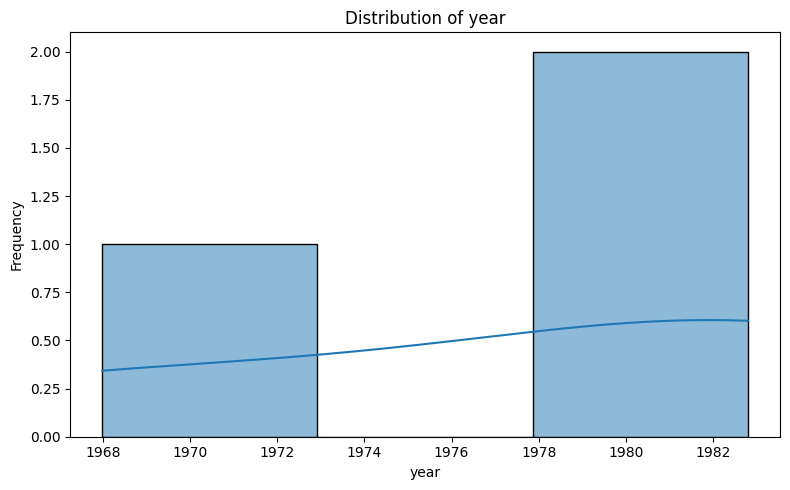

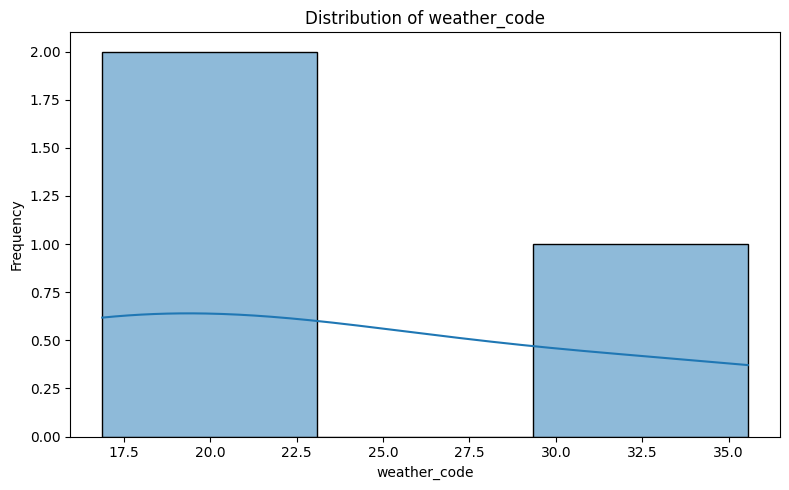

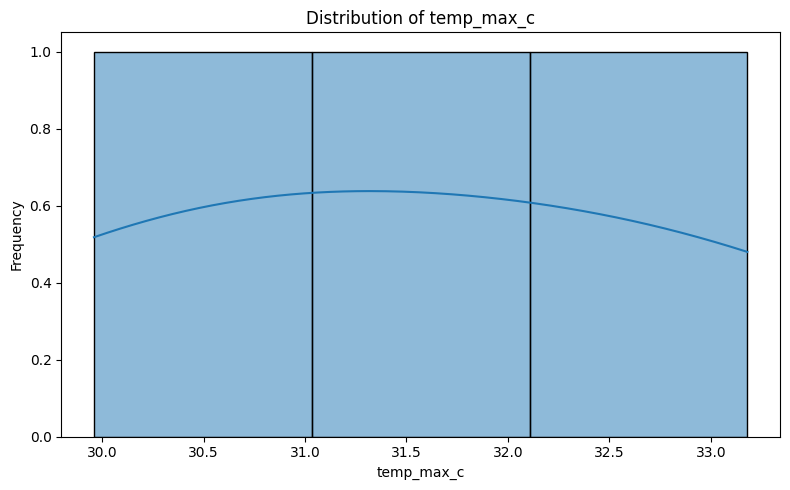

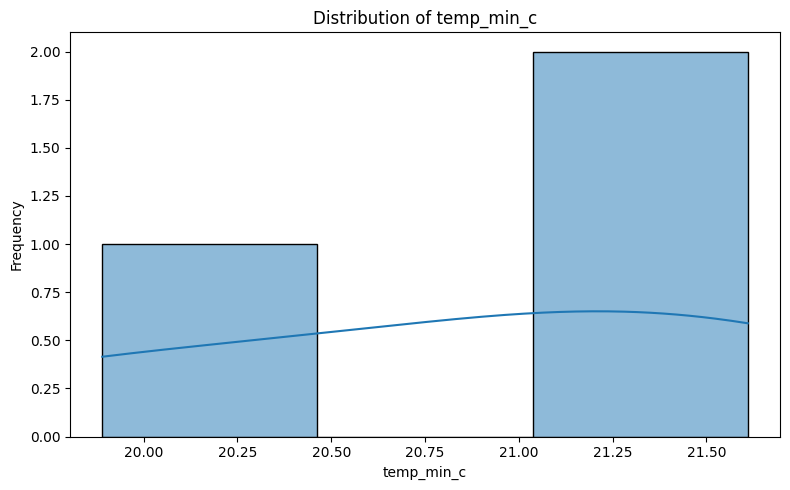

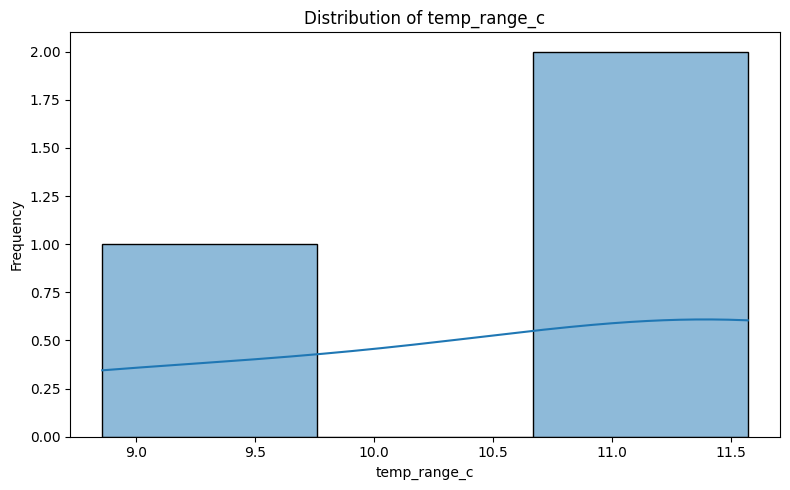

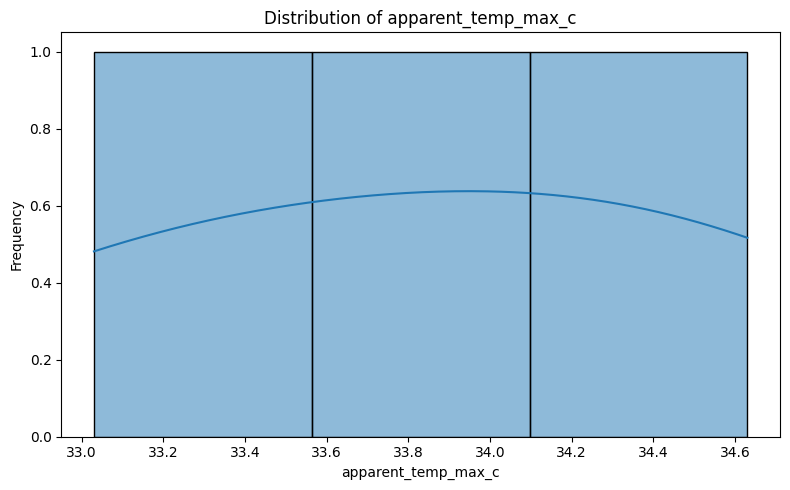

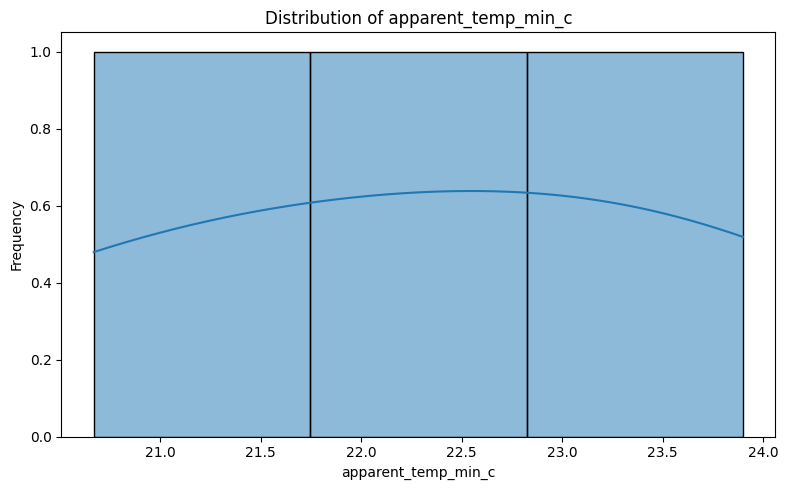

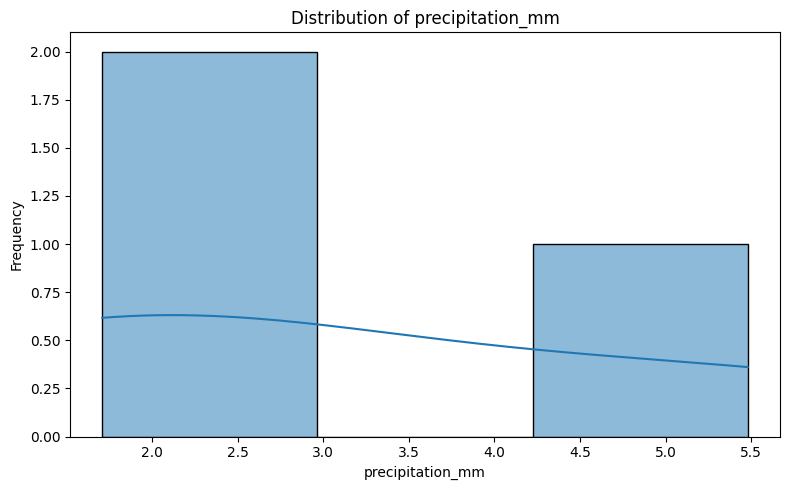

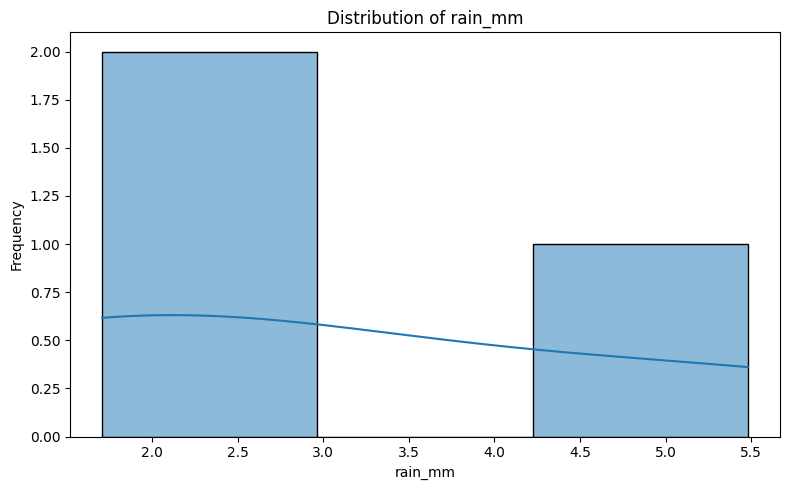

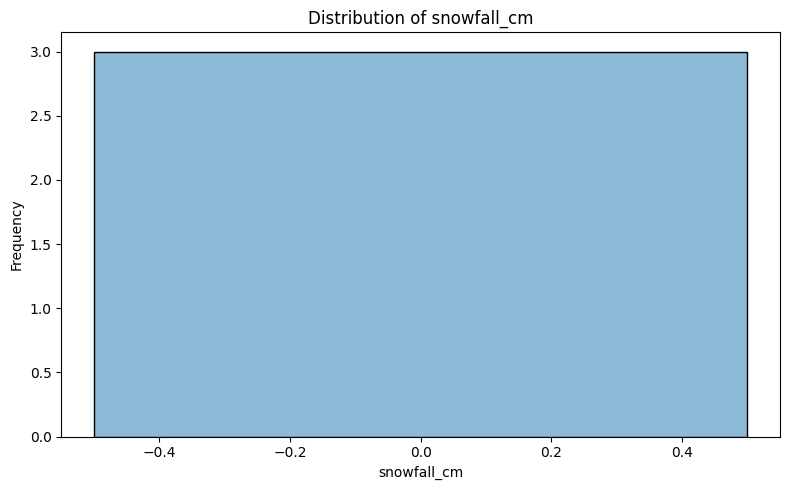

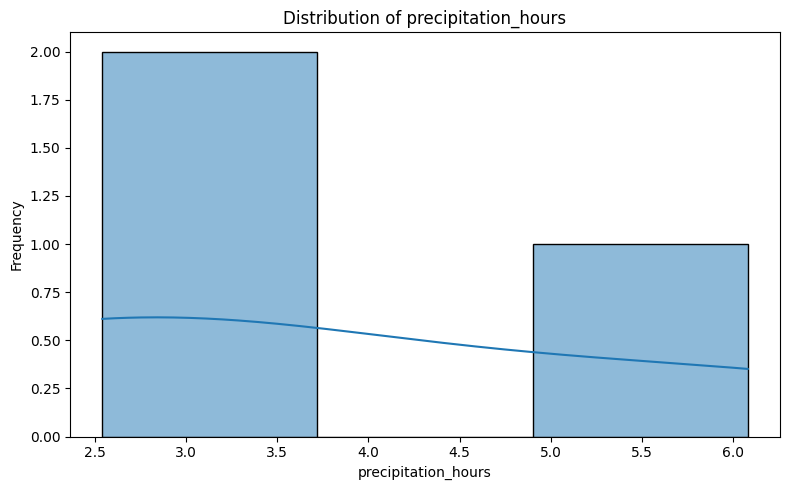

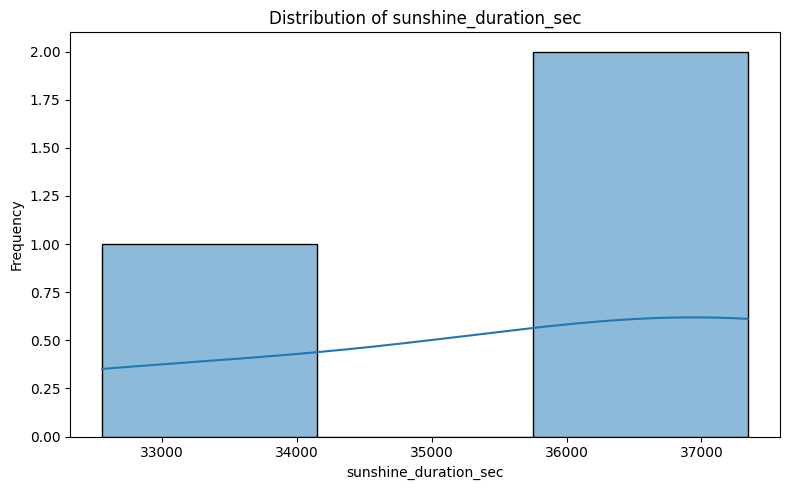

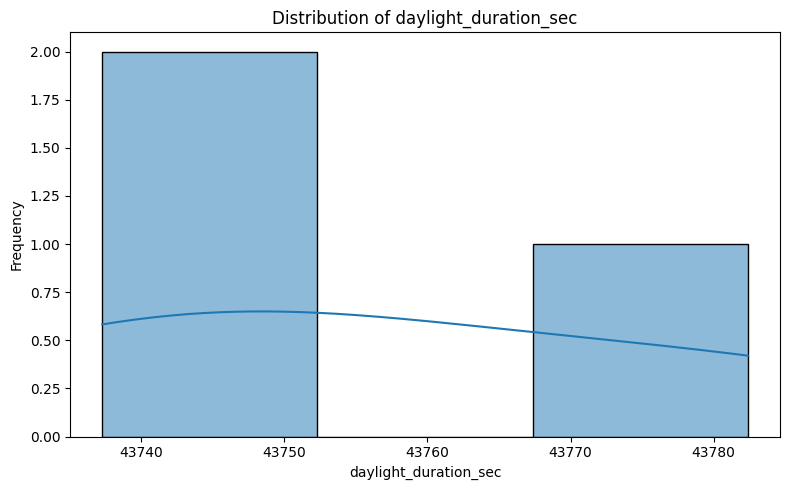

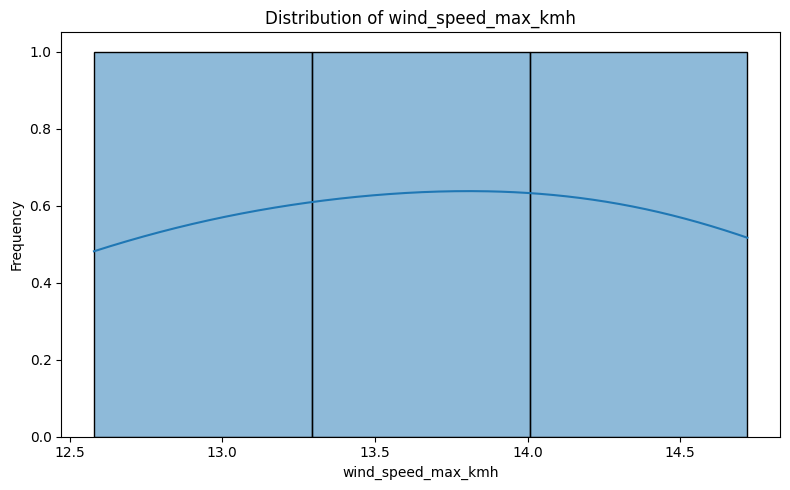

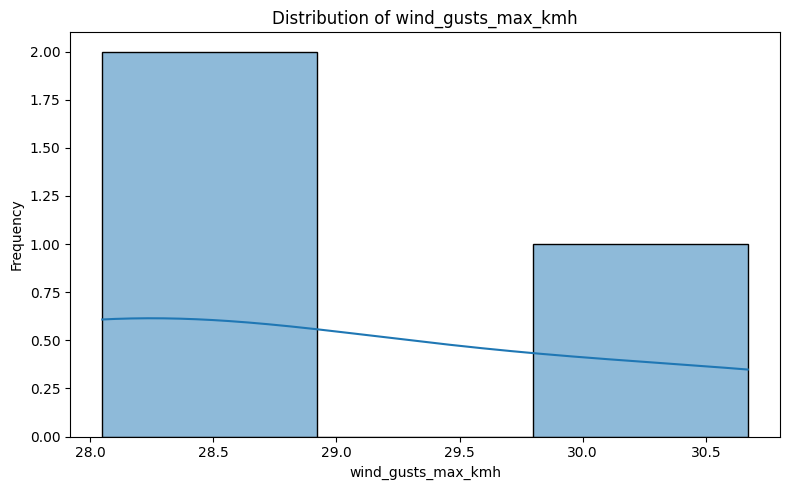

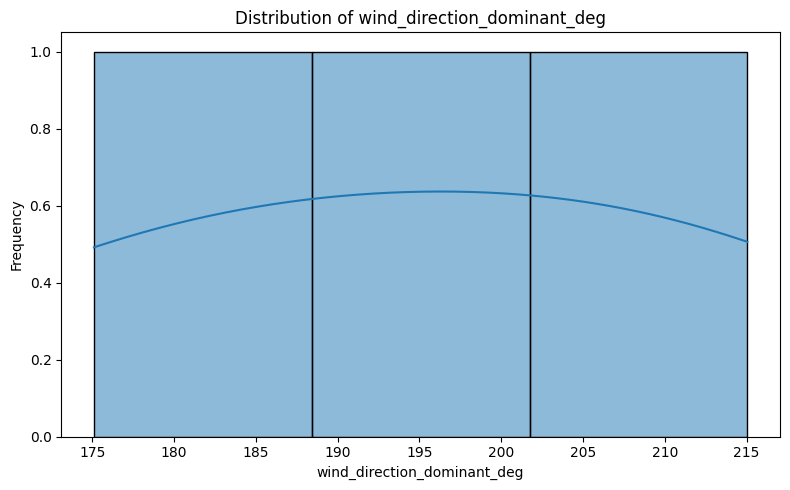

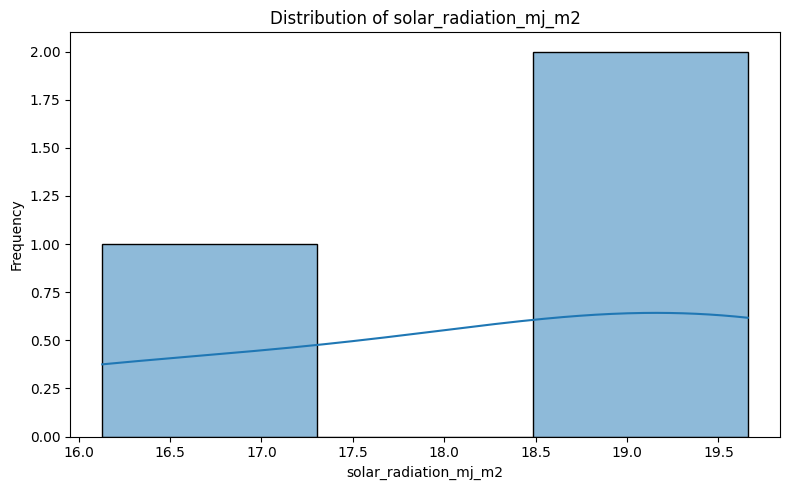

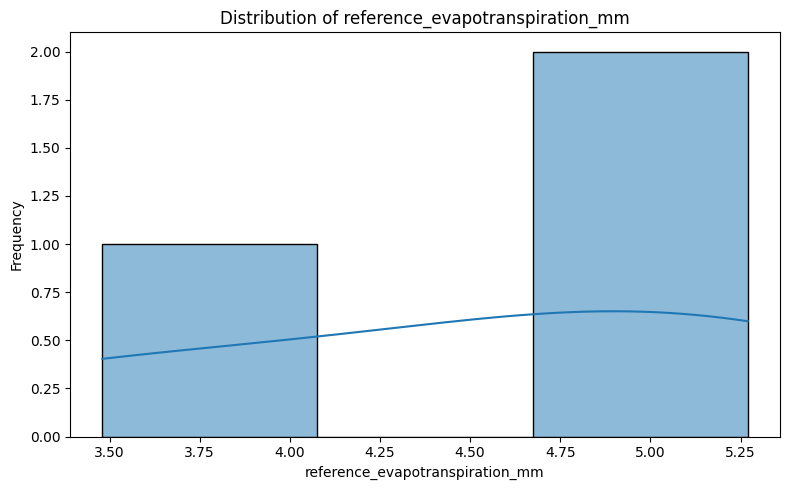

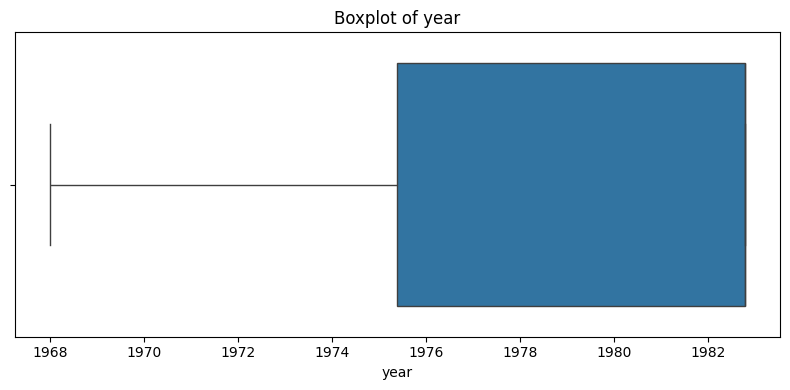

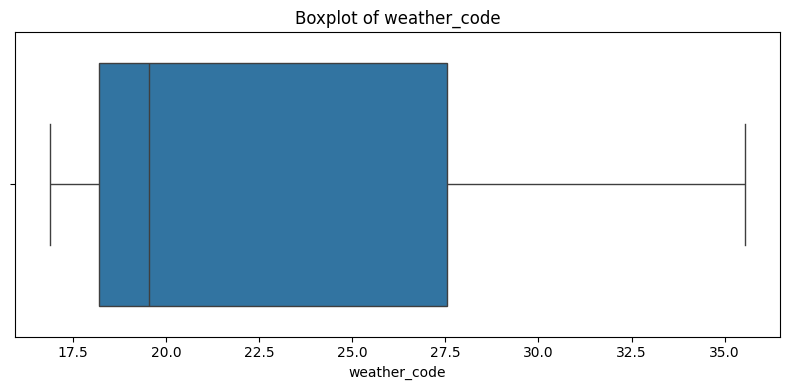

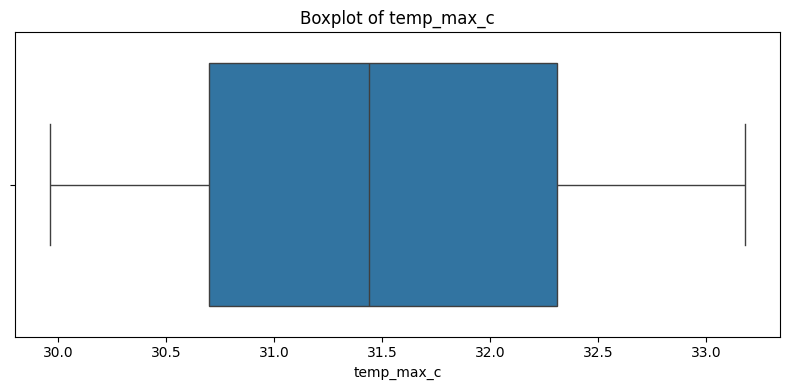

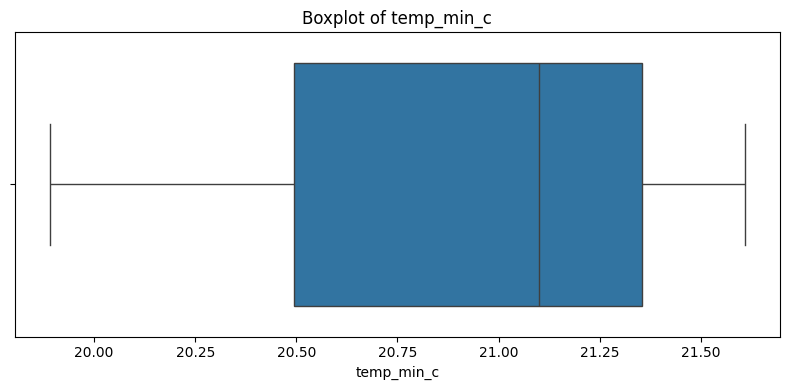

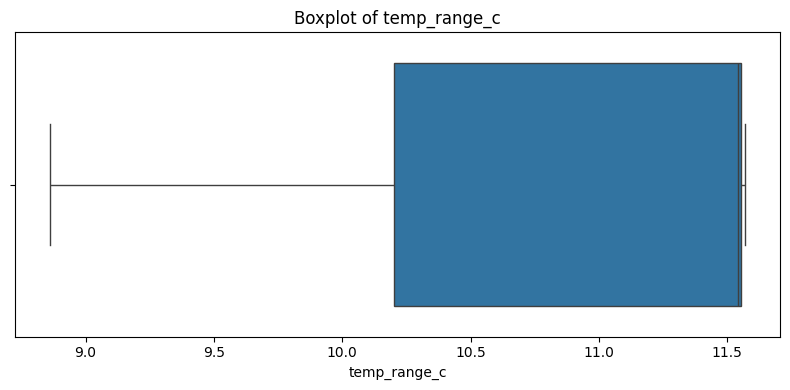

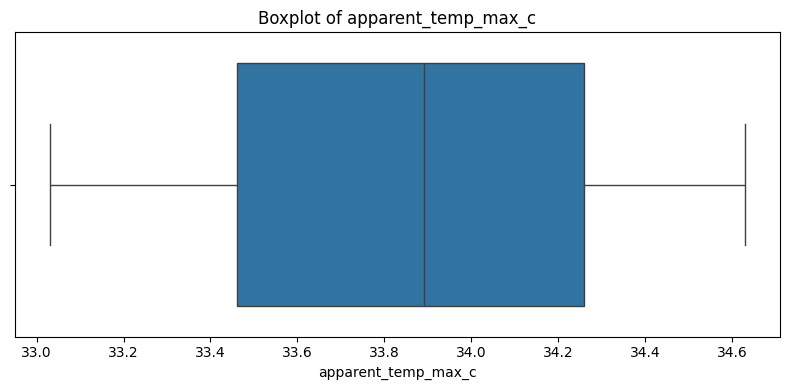

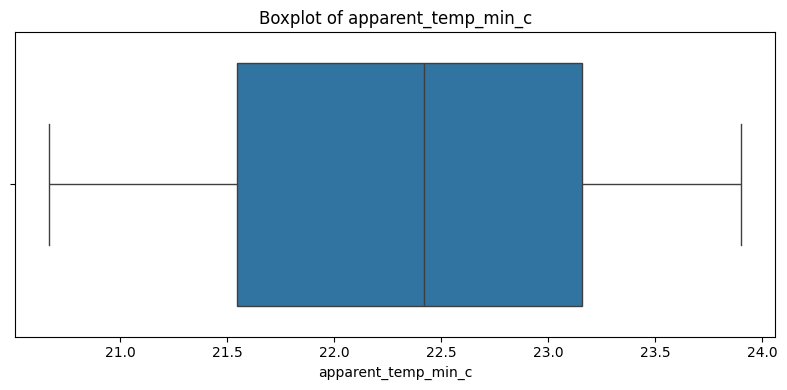

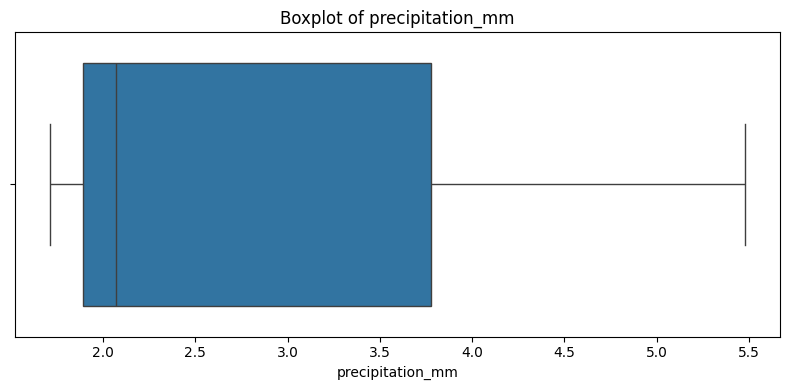

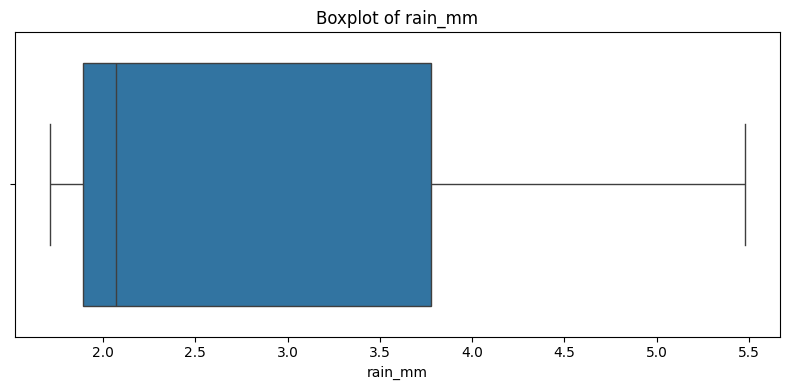

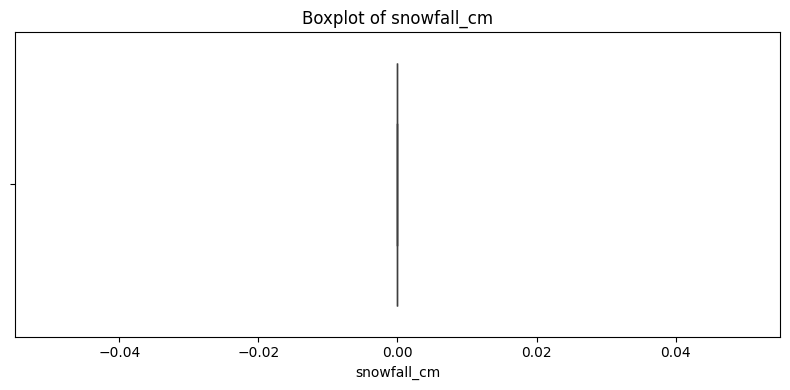

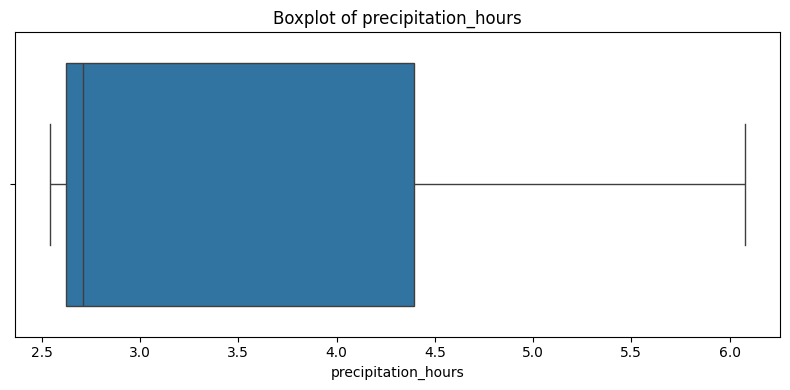

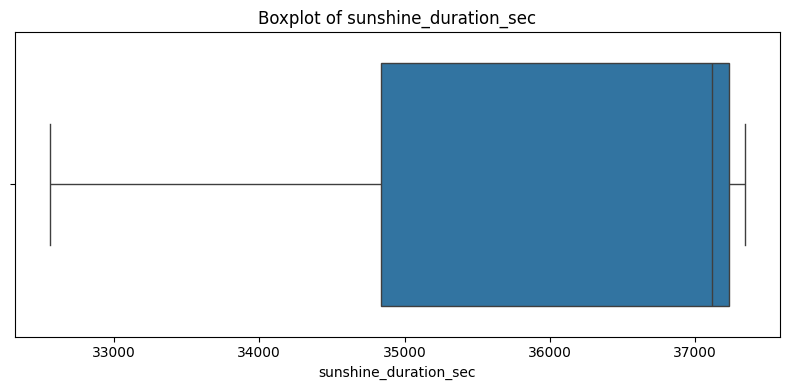

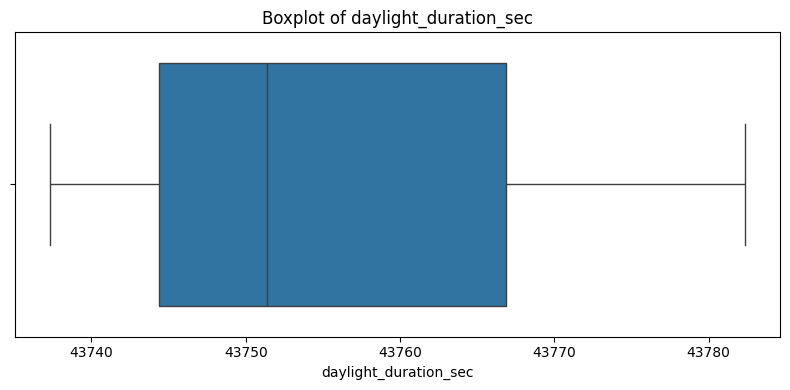

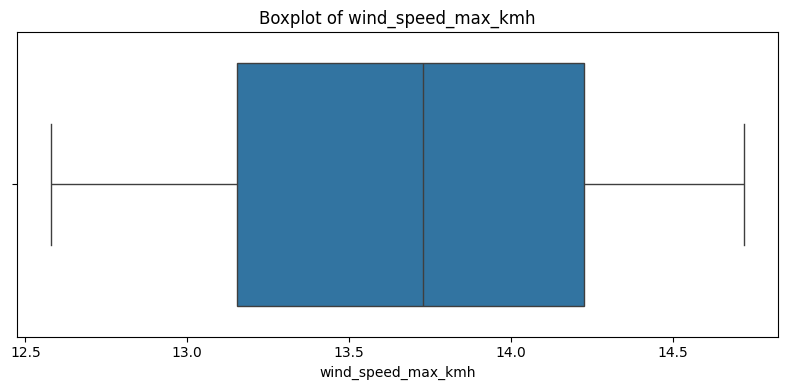

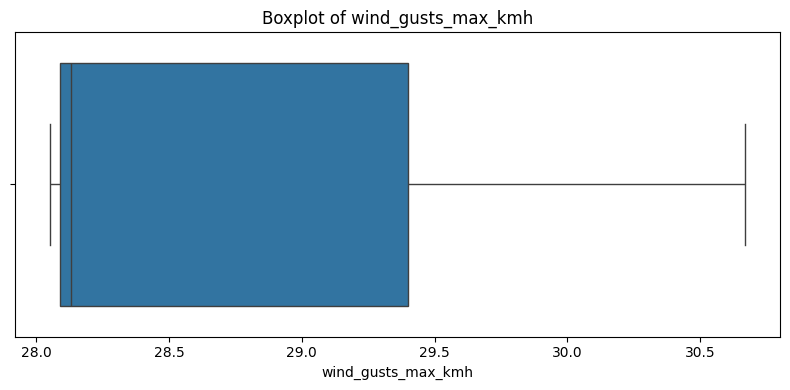

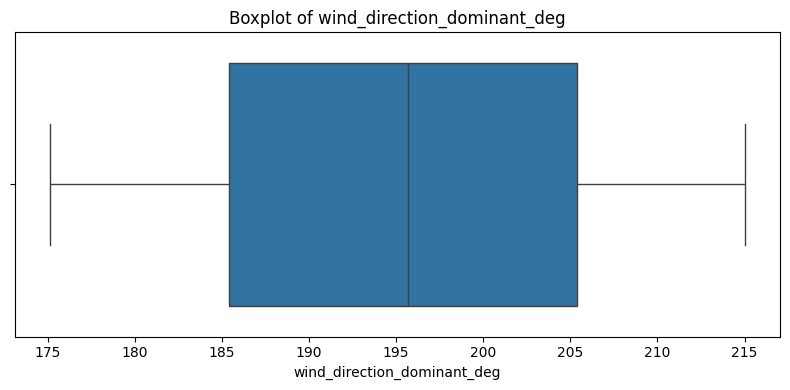

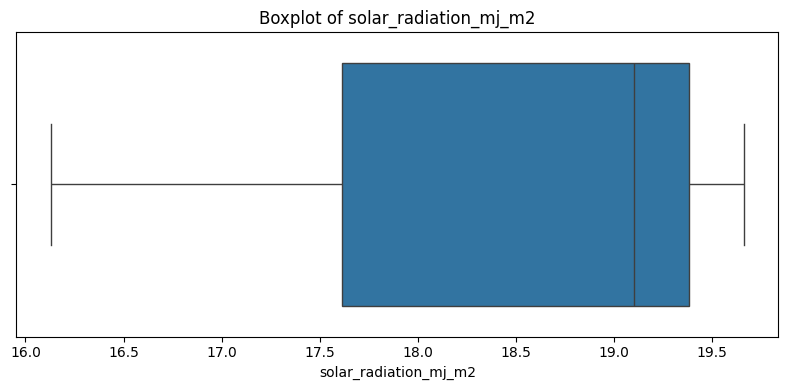

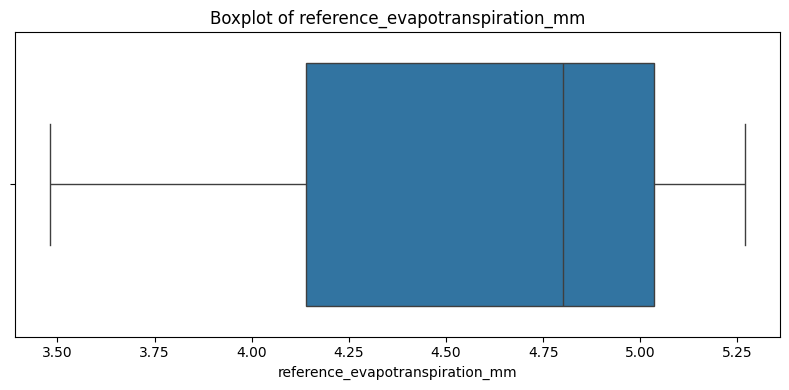


========== CORRELATION MATRIX ==========


,year,weather_code,temp_max_c,temp_min_c,temp_range_c,apparent_temp_max_c,apparent_temp_min_c,precipitation_mm,rain_mm,snowfall_cm,precipitation_hours,sunshine_duration_sec,daylight_duration_sec,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,solar_radiation_mj_m2,reference_evapotranspiration_mm
year,1.000000,0.609695,-0.888370,-0.728696,-0.508325,-0.843584,-0.048205,0.573052,0.573052,NaN,0.536416,-0.462922,0.741096,-0.843657,-0.999640,-0.017493,-0.622340,-0.703003
weather_code,0.609695,1.000000,-0.905557,0.098544,-0.992514,-0.088686,0.762324,0.998967,0.998967,NaN,0.995998,-0.984833,-0.080333,-0.939926,-0.630753,-0.803180,-0.999871,-0.992330
temp_max_c,-0.888370,-0.905557,1.000000,0.332923,0.846966,0.502864,-0.415771,-0.885347,-0.885347,NaN,-0.864019,0.818217,-0.350108,0.995977,0.900374,0.474599,0.912250,0.951053
temp_min_c,-0.728696,0.098544,0.332923,1.000000,-0.219344,0.982472,0.719168,0.143657,0.143657,NaN,0.187087,-0.269710,-0.999833,0.247091,0.710050,-0.671986,-0.082558,0.025229
temp_range_c,-0.508325,-0.992514,0.846966,-0.219344,1.000000,-0.033628,-0.835660,-0.997038,-0.997038,NaN,-0.999457,0.998651,0.201468,0.891197,0.531259,0.869925,0.990426,0.969803
apparent_temp_max_c,-0.843584,-0.088686,0.502864,0.982472,-0.033628,1.000000,0.577038,-0.043339,-0.043339,NaN,0.000688,-0.085480,-0.985716,0.423391,0.828865,-0.522158,0.104664,0.211138
apparent_temp_min_c,-0.048205,0.762324,-0.415771,0.719168,-0.835660,0.577038,1.000000,0.790942,0.790942,NaN,0.817114,-0.863053,-0.706344,-0.495590,0.021375,-0.997841,-0.751837,-0.676471
precipitation_mm,0.573052,0.998967,-0.885347,0.143657,-0.997038,-0.043339,0.790942,1.000000,1.000000,NaN,0.999030,-0.991699,-0.125538,-0.923445,-0.594845,-0.829418,-0.998109,-0.985688
rain_mm,0.573052,0.998967,-0.885347,0.143657,-0.997038,-0.043339,0.790942,1.000000,1.000000,NaN,0.999030,-0.991699,-0.125538,-0.923445,-0.594845,-0.829418,-0.998109,-0.985688
snowfall_cm,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


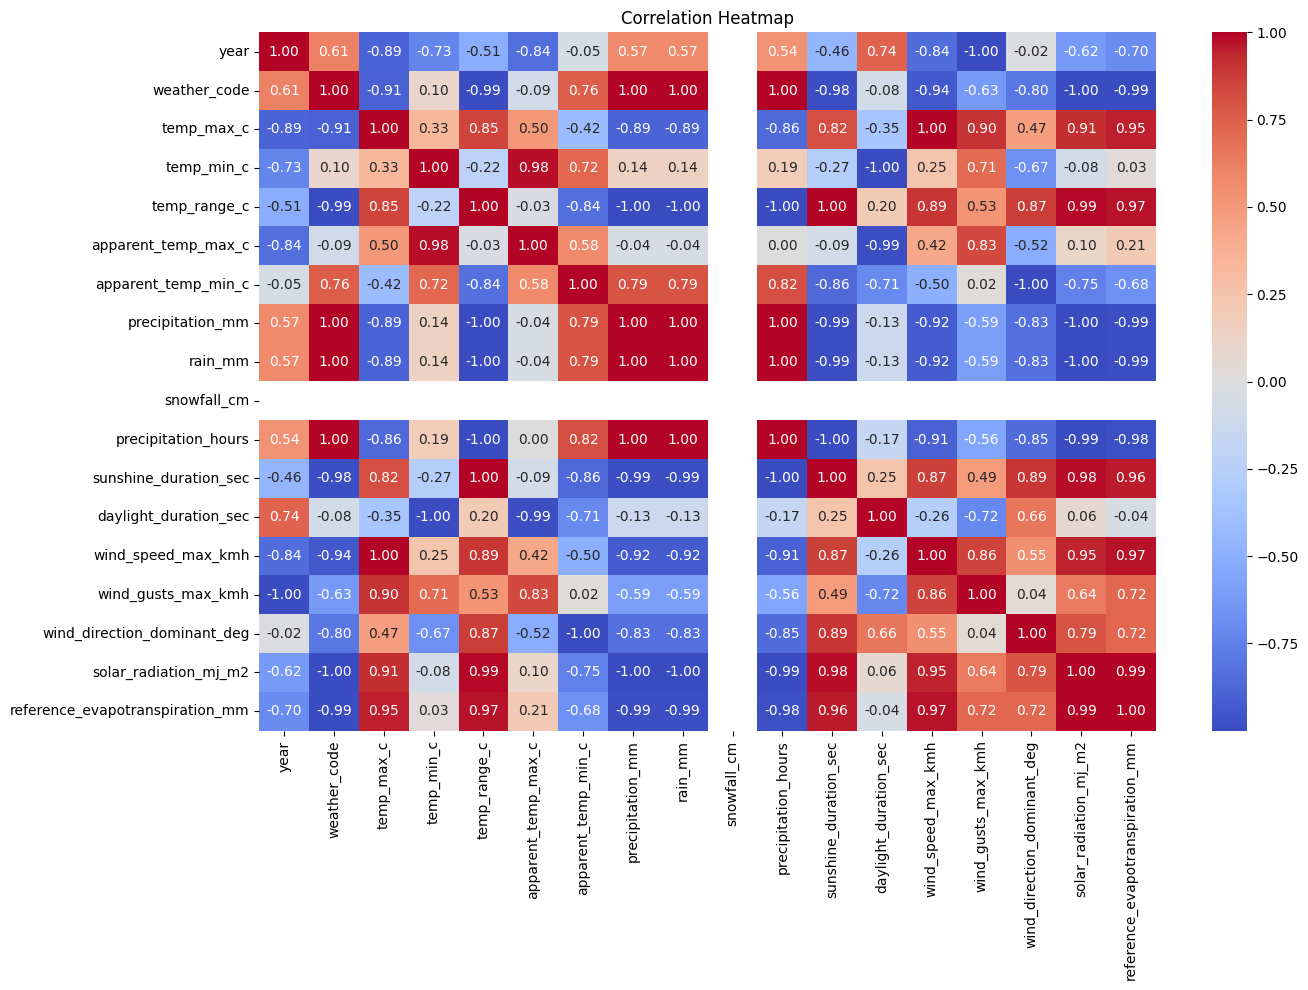

In [ ]:

# ------------------------------------------------------------
# 3. LAST 5 ROWS
# ------------------------------------------------------------

print("\n========== LAST 5 ROWS ==========")
display(state_wise_df.tail())


# ------------------------------------------------------------
# 4. STATISTICAL SUMMARY
# ------------------------------------------------------------

print("\n========== STATISTICAL SUMMARY ==========")
display(state_wise_df.describe())


# ------------------------------------------------------------
# 5. NUMBER OF STATES
# ------------------------------------------------------------

print("\n========== NUMBER OF STATES ==========")
print("Total States:", state_wise_df["state"].nunique())


# ------------------------------------------------------------
# 6. STATE LIST
# ------------------------------------------------------------

print("\n========== STATES ==========")
print(state_wise_df["state"].tolist())


# ------------------------------------------------------------
# 7. MISSING VALUES
# ------------------------------------------------------------

print("\n========== MISSING VALUES ==========")

missing_values = state_wise_df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": (
        missing_values / len(state_wise_df) * 100
    ).round(2)
})

display(missing_table)


# ------------------------------------------------------------
# 8. DUPLICATE VALUES
# ------------------------------------------------------------

print("\n========== DUPLICATE ROWS ==========")
print(
    "Number of duplicate rows:",
    state_wise_df.duplicated().sum()
)


# ------------------------------------------------------------
# 9. DATA TYPES
# ------------------------------------------------------------

print("\n========== DATA TYPES ==========")
display(
    pd.DataFrame({
        "Column": state_wise_df.columns,
        "Data Type": state_wise_df.dtypes.astype(str)
    })
)


# ------------------------------------------------------------
# 10. UNIQUE VALUES
# ------------------------------------------------------------

print("\n========== UNIQUE VALUES ==========")

for column in state_wise_df.columns:
    print(
        f"{column}: {state_wise_df[column].nunique()} unique values"
    )


# ------------------------------------------------------------
# 11. NUMERIC COLUMNS
# ------------------------------------------------------------

numeric_columns = state_wise_df.select_dtypes(
    include=np.number
).columns.tolist()

print("\n========== NUMERIC COLUMNS ==========")
print(numeric_columns)


# ------------------------------------------------------------
# 12. DISTRIBUTION OF NUMERIC FEATURES
# ------------------------------------------------------------

for column in numeric_columns:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        state_wise_df[column],
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 13. BOXPLOTS FOR OUTLIER DETECTION
# ------------------------------------------------------------

for column in numeric_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        x=state_wise_df[column]
    )

    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 14. CORRELATION MATRIX
# ------------------------------------------------------------

print("\n========== CORRELATION MATRIX ==========")

correlation_matrix = state_wise_df[
    numeric_columns
].corr()

display(correlation_matrix)


# ------------------------------------------------------------
# 15. CORRELATION HEATMAP
# ------------------------------------------------------------

plt.figure(
    figsize=(14, 10)
)

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 16. TEMPERATURE COMPARISON BY STATE
# ------------------------------------------------------------

if "temp_max" in state_wise_df.columns:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=state_wise_df,
        x="state",
        y="temp_max"
    )

    plt.title("Average Maximum Temperature by State")
    plt.xlabel("State")
    plt.ylabel("Temperature")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 17. MINIMUM TEMPERATURE BY STATE
# ------------------------------------------------------------

if "temp_min" in state_wise_df.columns:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=state_wise_df,
        x="state",
        y="temp_min"
    )

    plt.title("Average Minimum Temperature by State")
    plt.xlabel("State")
    plt.ylabel("Temperature")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


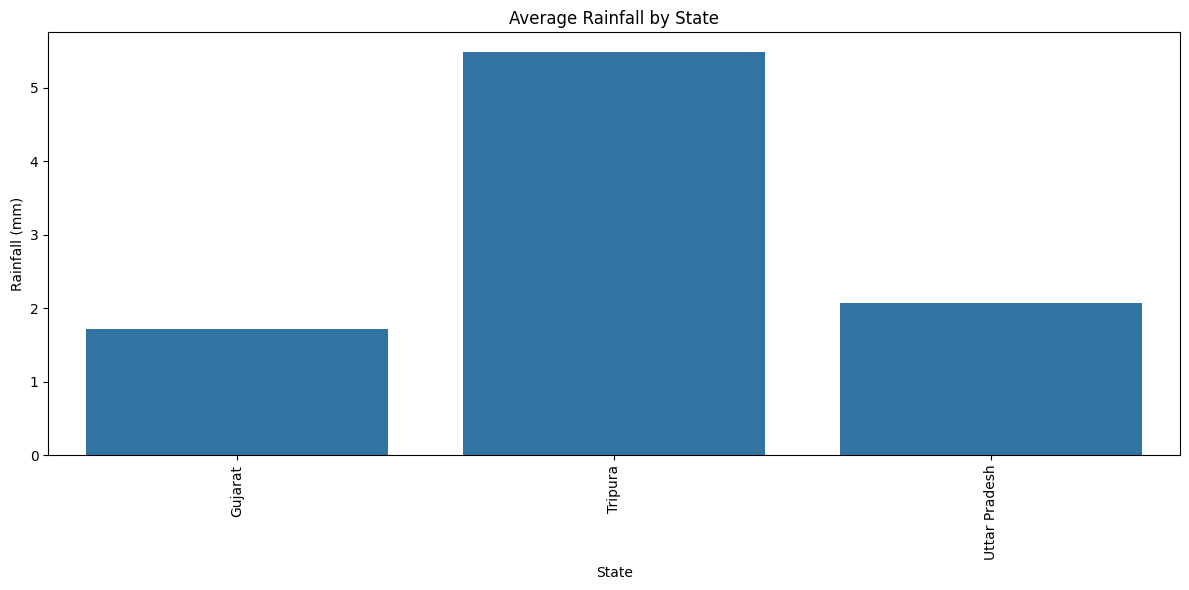


EDA COMPLETED SUCCESSFULLY
Number of states: 3
Number of features: 19
Missing values: 0
Duplicate rows: 0


In [ ]:


# ------------------------------------------------------------
# 18. RAINFALL BY STATE
# ------------------------------------------------------------

if "rain_mm" in state_wise_df.columns:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=state_wise_df,
        x="state",
        y="rain_mm"
    )

    plt.title("Average Rainfall by State")
    plt.xlabel("State")
    plt.ylabel("Rainfall (mm)")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 19. SUNSHINE DURATION BY STATE
# ------------------------------------------------------------

if "sunshine_duration" in state_wise_df.columns:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=state_wise_df,
        x="state",
        y="sunshine_duration"
    )

    plt.title("Average Sunshine Duration by State")
    plt.xlabel("State")
    plt.ylabel("Sunshine Duration")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 20. FINAL EDA SUMMARY
# ------------------------------------------------------------

print("\n========================================")
print("EDA COMPLETED SUCCESSFULLY")
print("========================================")

print("Number of states:",
      state_wise_df["state"].nunique())

print("Number of features:",
      len(state_wise_df.columns))

print("Missing values:",
      state_wise_df.isnull().sum().sum())

print("Duplicate rows:",
      state_wise_df.duplicated().sum())